# 06 Sensitive Questions and Survey Experiments

**Setting:** an employee survey asking about workplace misconduct
(falsifying time records), followed by a conjoint experiment on job
offers.
**Methods:** list experiment (item count technique) with a design-effect
test, forced-response randomized response, and AMCE estimation for a
forced-choice conjoint with respondent-clustered standard errors.
**Ground truth:** 22% of employees truly engaged in the behavior; only
55% of them admit it when asked directly. Conjoint AMCEs are computed
exactly by enumerating all 108 x 108 profile pairs under the
data-generating model.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
_root = pathlib.Path.cwd()
if _root.name == "notebooks":
    _root = _root.parent
sys.path.insert(0, str(_root / "src"))
FIG_DIR = _root / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})
# Categorical slots (validated palette), plus ink for the known truth
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED = "#0b0b0b", "#8a8984"

In [2]:
from surveyhub.simulate import simulate_sensitive, simulate_conjoint, true_amce
from surveyhub.experiments import (direct_estimate, list_experiment, list_design_test,
                                   randomized_response, amce)
TRUE_PREV = 0.22

## 1. Three ways to ask a sensitive question

Respondents are randomized into arms:

* **Direct (n = 1,000):** "Have you ever falsified a time record?"
* **List experiment (n = 2,000):** "How many of these have you done?"
  The control half sees four innocuous items; the treatment half sees
  the same four plus the sensitive one. Nobody reveals which items.
* **Randomized response (n = 1,000):** a private die roll tells the
  respondent to answer truthfully (4 in 6), say "yes" (1 in 6), or say
  "no" (1 in 6). A "yes" never identifies anyone.

In [3]:
sv = simulate_sensitive(prevalence=TRUE_PREV, admit_rate=0.55, seed=61)
est = {
    "Direct question": direct_estimate(sv.direct),
    "List experiment": list_experiment(sv.list_count, sv.list_treat),
    "Randomized response": randomized_response(sv.rr_answer, sv.rr_design["p_truth"], sv.rr_design["p_yes"]),
}
print(f"{'design':<21s} {'estimate':>9s} {'SE':>7s}   95% CI           (truth {TRUE_PREV})")
for k, e in est.items():
    lo, hi = e.ci
    print(f"{k:<21s} {e.estimate:9.3f} {e.se:7.3f}   [{lo:.3f}, {hi:.3f}]")
dt = list_design_test(sv.list_count, sv.list_treat, sv.n_control_items)
print(f"\nlist design-effect test: min adjusted p = {dt.min_pvalue:.2f} "
      f"-> {'design effect detected' if dt.design_effect else 'no evidence of a design effect'}")

design                 estimate      SE   95% CI           (truth 0.22)
Direct question           0.121   0.010   [0.101, 0.141]
List experiment           0.169   0.045   [0.082, 0.256]
Randomized response       0.209   0.022   [0.166, 0.252]

list design-effect test: min adjusted p = 1.00 -> no evidence of a design effect


Privacy has a price: for the same total sample the indirect designs
carry much larger standard errors, because each answer is mixed with
noise on purpose. The next cell repeats the survey 500 times.

In [4]:
rows = {k: [] for k in est}
for s in range(500):
    sv_ = simulate_sensitive(prevalence=TRUE_PREV, admit_rate=0.55, seed=1000 + s)
    rows["Direct question"].append(direct_estimate(sv_.direct))
    rows["List experiment"].append(list_experiment(sv_.list_count, sv_.list_treat))
    rows["Randomized response"].append(randomized_response(sv_.rr_answer, sv_.rr_design["p_truth"],
                                                           sv_.rr_design["p_yes"]))
print(f"{'design':<21s} {'mean':>7s} {'bias':>7s} {'SD':>6s} {'coverage':>9s}")
for k, lst in rows.items():
    e = np.array([r.estimate for r in lst])
    c = np.mean([abs(r.estimate - TRUE_PREV) < 1.96 * r.se for r in lst])
    print(f"{k:<21s} {e.mean():7.3f} {e.mean() - TRUE_PREV:+7.3f} {e.std():6.3f} {c:9.1%}")

design                   mean    bias     SD  coverage
Direct question         0.120  -0.100  0.010      0.0%
List experiment         0.224  +0.004  0.043     95.2%
Randomized response     0.220  -0.000  0.022     95.0%


## 2. A conjoint experiment on job offers

Each of 1,500 respondents sees five pairs of job offers with randomized
salary, work location, employer type, manager rating and benefits, and
picks one. The average marginal component effect (AMCE) of a level is
the change in the probability that an offer is chosen when the
attribute moves from its baseline to that level, averaged over
everything else. Two respondent types differ in how much they value
remote work; the AMCE averages over them.

In [5]:
truth = true_amce()
cj = simulate_conjoint(n_respondents=1500, n_tasks=5, seed=62)
res = amce(cj.levels, cj.chosen, cj.respondent, cj.attributes)
print(f"{'attribute: level':<30s} {'truth':>7s} {'AMCE':>7s} {'SE (cl)':>8s} {'SE (naive)':>11s} {'z':>6s}")
for lab, e, s_c, s_n in zip(res.labels, res.estimate, res.se_cluster, res.se_naive):
    print(f"{lab[0] + ': ' + lab[1]:<30s} {truth[lab]:7.3f} {e:7.3f} {s_c:8.4f} {s_n:11.4f} "
          f"{(e - truth[lab]) / s_c:+6.2f}")

attribute: level                 truth    AMCE  SE (cl)  SE (naive)      z
Salary: +10%                     0.096   0.111   0.0095      0.0097  +1.60
Salary: +20%                     0.179   0.178   0.0094      0.0096  -0.14
Location: Hybrid                 0.119   0.123   0.0099      0.0096  +0.36
Location: Remote                 0.198   0.198   0.0100      0.0096  +0.01
Employer: Mid-size               0.020   0.018   0.0096      0.0097  -0.12
Employer: Large firm             0.017   0.003   0.0095      0.0096  -1.48
Manager rating: 4.5 stars        0.118   0.129   0.0077      0.0079  +1.38
Benefits: Generous               0.076   0.085   0.0079      0.0079  +1.15


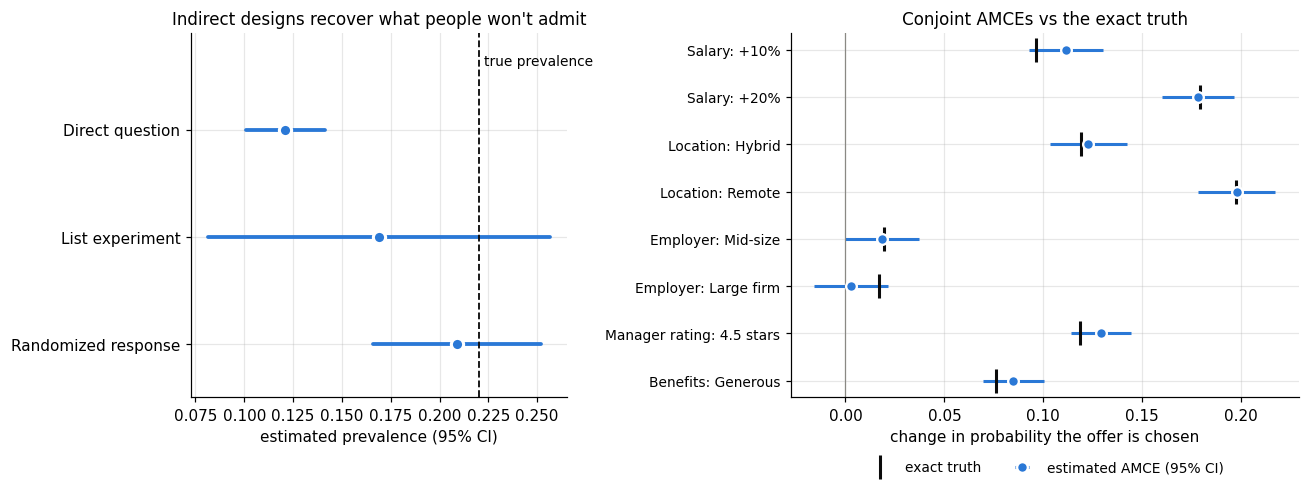

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.35]})
names = list(est)
for i, k in enumerate(names):
    e = est[k]
    lo, hi = e.ci
    ax1.plot([lo, hi], [i, i], color=BLUE, lw=2.5, solid_capstyle="round")
    ax1.plot(e.estimate, i, "o", color=BLUE, ms=8, markeredgecolor="white", markeredgewidth=2)
ax1.axvline(TRUE_PREV, color=INK, ls="--", lw=1.2)
ax1.text(TRUE_PREV + 0.003, -0.6, "true prevalence", ha="left", fontsize=9)
ax1.set_yticks(range(len(names)))
ax1.set_yticklabels(names)
ax1.set_ylim(len(names) - 0.5, -0.9)
ax1.set_xlabel("estimated prevalence (95% CI)")
ax1.set_title("Indirect designs recover what people won't admit", fontsize=11)

labels = [f"{a}: {l}" for a, l in res.labels]
yy = np.arange(len(labels))
ax2.errorbar(res.estimate, yy, xerr=1.96 * res.se_cluster, fmt="o", color=BLUE, ms=7,
             mec="white", mew=1.5, elinewidth=2, capsize=0, label="estimated AMCE (95% CI)")
ax2.plot([truth[l] for l in res.labels], yy, "|", color=INK, ms=16, mew=2, label="exact truth")
ax2.axvline(0, color=MUTED, lw=0.8)
ax2.set_yticks(yy)
ax2.set_yticklabels(labels, fontsize=9)
ax2.invert_yaxis()
ax2.set_xlabel("change in probability the offer is chosen")
ax2.set_title("Conjoint AMCEs vs the exact truth", fontsize=11)
ax2.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "sensitive_conjoint.png", dpi=150, bbox_inches="tight")
plt.show()

## Takeaways

* The direct question underestimates the behavior by almost half and
  its CI is confidently wrong. Both indirect designs are unbiased and
  their CIs cover the truth, at the cost of a much larger standard
  error, so they need bigger samples.
* Check the list experiment's assumptions: the design-effect test looks
  for signs that adding the sensitive item changed answers to the
  control items. Choose control items that avoid floor and ceiling
  effects.
* Conjoint AMCEs from a simple linear regression recover the exact
  truth because the attributes are randomized. Cluster standard errors
  by respondent, since each person contributes many choices.